In [1]:
import pandas as pd
import joblib
import os
from dotenv import load_dotenv
from conformist import FNRCoP, PredictionDataset, ValidationTrial

load_dotenv()

RANDOM_SEED = int(os.getenv("RANDOM_SEED", 42))
N_JOBS = int(os.getenv("N_JOBS", 10))
X_CALIBRATION_CSV_PATH = os.getenv("X_CALIBRATION_CSV_PATH")
Y_CALIBRATION_TSV_PATH = os.getenv("Y_CALIBRATION_TSV_PATH")
X_TEST_CSV_PATH = os.getenv("X_TEST_CSV_PATH")
Y_TEST_TSV_PATH = os.getenv("Y_TEST_TSV_PATH")
RF_MODEL_PATH = os.getenv("RF_MODEL_PATH")
SELECTED_FEATURES_PATH = os.getenv("SELECTED_FEATURES_PATH")
PREDS_CAL_CSV_PATH = os.getenv("PREDS_CAL_CSV_PATH")
PREDS_TEST_CSV_PATH = os.getenv("PREDS_TEST_CSV_PATH")
OUTPUT_DIR = os.getenv("OUTPUT_DIR")

# Print config
print(f"RANDOM_SEED: {RANDOM_SEED}")
print(f"N_JOBS: {N_JOBS}")
print(f"X_CALIBRATION_CSV_PATH: {X_CALIBRATION_CSV_PATH}")
print(f"Y_CALIBRATION_TSV_PATH: {Y_CALIBRATION_TSV_PATH}")
print(f"X_TEST_CSV_PATH: {X_TEST_CSV_PATH}")
print(f"Y_TEST_TSV_PATH: {Y_TEST_TSV_PATH}")
print(f"RF_MODEL_PATH: {RF_MODEL_PATH}")
print(f"SELECTED_FEATURES_PATH: {SELECTED_FEATURES_PATH}")
print(f"PREDS_CAL_CSV_PATH: {PREDS_CAL_CSV_PATH}")
print(f"PREDS_TEST_CSV_PATH: {PREDS_TEST_CSV_PATH}")
print(f"OUTPUT_DIR: {OUTPUT_DIR}")

RANDOM_SEED: 42
N_JOBS: 10
X_CALIBRATION_CSV_PATH: /home/mariya/Data/pallas/nf-core-gexml-output-cal/transpose/transposed.csv
Y_CALIBRATION_TSV_PATH: /home/mariya/Data/pallas/nf-core-gexml-output-cal/class/subtypes.tsv
X_TEST_CSV_PATH: /home/mariya/Data/pallas/nf-core-gexml-output-test/transpose/transposed.csv
Y_TEST_TSV_PATH: /home/mariya/Data/pallas/nf-core-gexml-output-test/class/subtypes.tsv
RF_MODEL_PATH: /home/mariya/Data/pallas/training/final_model.pkl
SELECTED_FEATURES_PATH: /home/mariya/Data/pallas/training/selected_features.pkl
PREDS_CAL_CSV_PATH: /home/mariya/Data/pallas/conformal_prediction/gex_calibration_probs.csv
PREDS_TEST_CSV_PATH: /home/mariya/Data/pallas/conformal_prediction/gex_test_probs.csv
OUTPUT_DIR: /home/mariya/Data/pallas/conformal_prediction


In [2]:
# Load the model
rf = joblib.load(RF_MODEL_PATH)

# Load selected features
selected_features = joblib.load(SELECTED_FEATURES_PATH)

In [3]:
# Load calibration data
X_calibration = pd.read_csv(X_CALIBRATION_CSV_PATH, index_col=0)
y_calibration = pd.read_csv(Y_CALIBRATION_TSV_PATH, index_col=0, sep="\t").squeeze()
X_calibration = X_calibration[selected_features]
X_calibration = X_calibration.loc[y_calibration.index]
X_calibration.shape, y_calibration.shape

((486, 3934), (486,))

In [4]:
# Load test data
X_test = pd.read_csv(X_TEST_CSV_PATH, index_col=0)
y_test = pd.read_csv(Y_TEST_TSV_PATH, index_col=0, sep="\t").squeeze()
X_test = X_test[selected_features]
X_test = X_test.loc[y_test.index]
X_test.shape, y_test.shape

((464, 3934), (464,))

In [5]:
def format_probabilities_for_conformist(model, X, y, path):
    probs = model.predict_proba(X)
    preds = model.predict(X)

    df = pd.DataFrame(index=X.index)

    # Add a column with known_class
    df["known_class"] = y

    # Add a column with the predicted class
    df["predicted_class"] = preds

    probs_df = pd.DataFrame(probs, columns=model.classes_, index=X.index)
    df = pd.concat([df, probs_df], axis=1)

    # Rename index to "id"
    df = df.rename_axis("id")

    # Save
    df.to_csv(path)

In [6]:
format_probabilities_for_conformist(rf, X_calibration, y_calibration, PREDS_CAL_CSV_PATH)
format_probabilities_for_conformist(rf, X_test, y_test, PREDS_TEST_CSV_PATH)

In [7]:
# Read in formatted predictions
calpd = PredictionDataset(predictions_csv=PREDS_CAL_CSV_PATH, dataset_name='cal')
testpd = PredictionDataset(predictions_csv=PREDS_TEST_CSV_PATH, dataset_name='test')
calpd, testpd

(<conformist.prediction_dataset.PredictionDataset at 0x7f8a8e6a7790>,
 <conformist.prediction_dataset.PredictionDataset at 0x7f8b0c270580>)

In [12]:
# First, check for rare classes in the calibration dataset
class_counts = calpd.df['known_class'].value_counts()
print("Class distribution in calibration data:")
print(class_counts)

# Filter out rare classes (optional)
MIN_SAMPLES = 5  # Minimum samples required per class
rare_classes = class_counts[class_counts < MIN_SAMPLES].index.tolist()
if rare_classes:
    print(f"Warning: Found {len(rare_classes)} classes with fewer than {MIN_SAMPLES} samples: {rare_classes}")
    print("These rare classes may cause numerical issues in conformal prediction")

# Modify alpha to be more conservative when working with small datasets
# Smaller alpha -> larger prediction sets -> more conservative
ALPHA = 0.05  # Try a smaller alpha (was 0.1)

mcp = FNRCoP(calpd, alpha=ALPHA)
mcp.calibrate()

# # Try with more regularization
# mcp = FNRCoP(calpd, alpha=ALPHA)

# # Use try/except to handle potential errors
# try:
#     trial = mcp.do_validation_trial(n_runs=10)
#     trial.run_reports(OUTPUT_DIR)
# except ValueError as e:
#     print(f"Error during conformal calibration: {e}")
#     print("Trying with even more conservative settings...")

#     # Try with even smaller alpha as a fallback
#     mcp = FNRCoP(calpd, alpha=0.01)
#     trial = mcp.do_validation_trial(n_runs=5)  # Fewer runs as a fallback
#     trial.run_reports(OUTPUT_DIR)

Class distribution in calibration data:
known_class
B-ALL, high hyperdiploid    84
B-ALL, ETV6::RUNX1          70
B-ALL, BCR::ABL1-like       56
B-ALL, KMT2A-r              33
B-ALL, PAX5alt              31
T-ALL                       26
B-ALL, DUX4-r               24
B-ALL, BCR::ABL1            21
B-ALL, TCF3::PBX1           19
B-ALL, hypodiploid          19
AML, KMT2A-r                16
AML, RUNX1::RUNX1T1         14
B-ALL, ZNF384-r             12
AML, CBFB::MYH11            10
B-ALL, ETV6::RUNX1-like      9
B-ALL, iAMP21                8
B-ALL, MEF2D-r               8
B-ALL, PAX5 P80R             5
AML, NPM1alt                 4
B-ALL, NUTM1-r               3
AML, CEBPAalt                3
AML, NUP98-r                 3
B-ALL, MYC-r                 2
Non-leukemic                 2
B-ALL, HLF-r                 1
B-ALL, IKZF1 N159Y           1
AML, CBFA2T3::GLIS2          1
AML, APL-PML::RARA           1
Name: count, dtype: int64
These rare classes may cause numerical issues in confo

[np.float64(0.0625000000937499), np.float64(0.020833333431249934), np.float64(0.04166666676249997), np.float64(0.020833333431249934), np.float64(0.08333333342500004), np.float64(1.000000082740371e-10), np.float64(0.10416666675624997), np.float64(0.10416666675624997), np.float64(0.12500000008750012), np.float64(0.020833333431249934), np.float64(0.08333333342500004), np.float64(0.020833333431249934), np.float64(0.020833333431249934), np.float64(0.020833333431249934), np.float64(0.08333333342500004), np.float64(0.04166666676249997), np.float64(0.020833333431249934), np.float64(0.020833333431249934), np.float64(1.000000082740371e-10), np.float64(0.04166666676249997), np.float64(0.0625000000937499), np.float64(1.000000082740371e-10), np.float64(1.000000082740371e-10), np.float64(0.0625000000937499), np.float64(0.0625000000937499), np.float64(0.020833333431249934), np.float64(1.000000082740371e-10), np.float64(0.020833333431249934), np.float64(0.08333333342500004), np.float64(1.0000000827403

<Figure size 400x300 with 0 Axes>

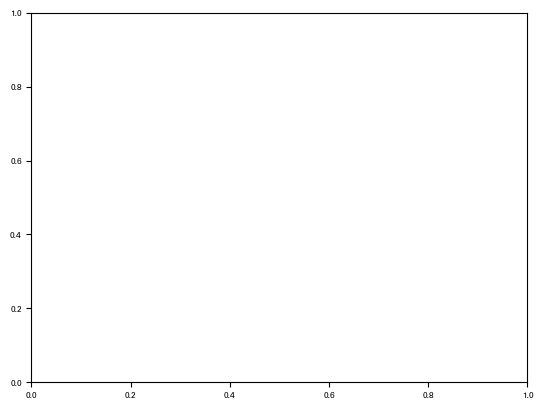

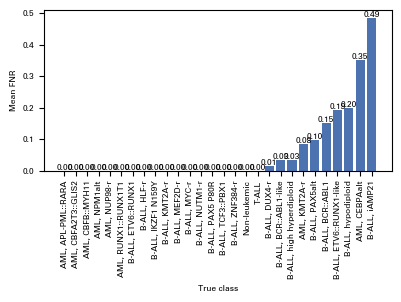

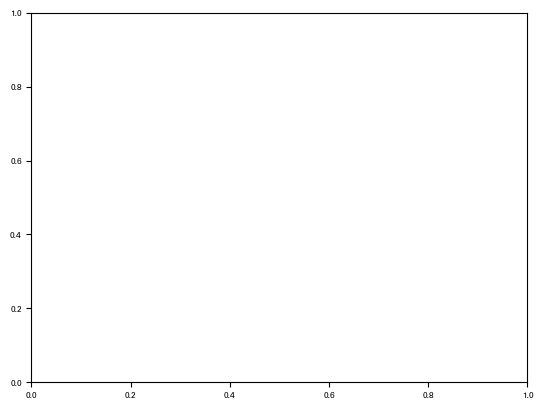

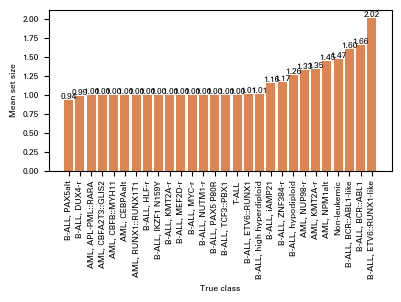

In [13]:
ALPHA=0.05

# Validation trial and reports
mcp = FNRCoP(calpd, alpha=ALPHA)
trial = mcp.do_validation_trial(n_runs=1000)
trial.run_reports(OUTPUT_DIR)


/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are sett

Saving upset plot to /home/mariya/Data/pallas/conformal_prediction/FNRCoP/2025-09-20_20-41-22/upset_plot.pdf


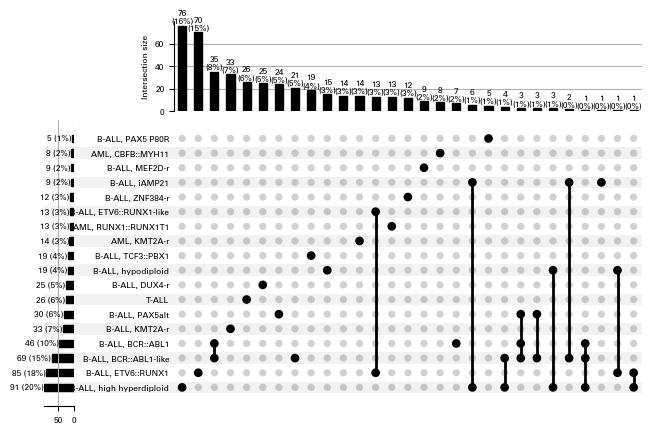

In [14]:
formatted_predictions = mcp.predict(testpd,
                                    OUTPUT_DIR)